# Crop suitability exposure (GAEZ v4)

## 1. Sample and GAEZ rasters

In [1]:
import os

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio import features

BASE = "https://raw.githubusercontent.com/AndrewEberhardt/DataScienceProject/main/data/"
PROCESSED_OUT = "../data/processed/"
FIGURES = "../figures/"

CROPS = {"palm": "olp", "soy": "soy"}  # GAEZ crop codes
SUITABLE = 4000  # GAEZ index threshold: class "medium" or better
THRESHOLDS = [2500, 4000, 5500]  # moderate or better, medium or better, good or better

In [2]:
# 62-country sample, one row per country
sample = (pd.read_csv(BASE + "processed/shock_panel.csv")[["iso3", "country", "region"]]
            .drop_duplicates().sort_values("iso3").reset_index(drop=True))
assert len(sample) == 62

# GAEZ v4, theme 4, CRU TS 3.2, 1961-1990, rainfed. H = high input (main), L = low input (robustness)
# sx: suitability index 0-10000, sx1: share of the cell very suitable or suitable (0-10000)
RASTERS = {f"{v}_{crop}": f"raw/gaez/{v}r_{code}.tif"
           for crop, code in CROPS.items() for v in ["sxH", "sxL", "sx1L"]}
RASTERS["si_palm"] = "raw/gaez/siLr_olp.tif"  # suitability class: 0 ocean, 9 inland water


def read_raster(path):
    """Read a GAEZ GeoTIFF from GitHub, nodata (-9) as NaN."""
    with rasterio.open(BASE + path) as src:
        values = src.read(1).astype(float)
        if src.nodata is not None:
            values[values == src.nodata] = np.nan
        return values, src.transform, src.shape, src.crs


grids = {}
for name, path in RASTERS.items():
    grids[name], transform, shape, crs = read_raster(path)

assert crs.to_epsg() == 4326 and shape == (2160, 4320)
assert len({g.shape for g in grids.values()}) == 1
print({name: (np.nanmin(g), np.nanmax(g)) for name, g in grids.items()})

{'sxH_palm': (np.float64(0.0), np.float64(8690.0)), 'sxL_palm': (np.float64(0.0), np.float64(10000.0)), 'sx1L_palm': (np.float64(0.0), np.float64(10000.0)), 'sxH_soy': (np.float64(0.0), np.float64(10000.0)), 'sxL_soy': (np.float64(0.0), np.float64(10000.0)), 'sx1L_soy': (np.float64(0.0), np.float64(10000.0)), 'si_palm': (np.float64(0.0), np.float64(9.0))}


In [3]:
# Area of each 5 arc-minute cell (ha): cells shrink towards the poles, so counting cells is not enough
R_EARTH = 6_371_007.2  # authalic radius (m)
res = abs(transform.e)  # cell size in degrees
lat_top = transform.f - res * np.arange(shape[0])
cell_m2 = (R_EARTH ** 2 * np.deg2rad(res)
           * (np.sin(np.deg2rad(lat_top)) - np.sin(np.deg2rad(lat_top - res))))
cell_ha = np.repeat((cell_m2 / 10_000)[:, None], shape[1], axis=1)

# Land cells: a GAEZ value and not inland water (large lakes such as Lake Victoria or Lake Malawi)
land_cells = ~np.isnan(grids["sxH_palm"]) & (grids["si_palm"] != 9)
print("Inland water cells removed:", int((~np.isnan(grids["sxH_palm"]) & (grids["si_palm"] == 9)).sum()))
# Check: total land area covered by GAEZ, close to 13-15 billion ha
print("GAEZ land area (billion ha):", round(cell_ha[land_cells].sum() / 1e9, 2))

Inland water cells removed: 20565
GAEZ land area (billion ha): 13.67


In [4]:
# Country of each cell from Natural Earth borders (same borders as the sample definition)
url_borders = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/"
               "master/geojson/ne_50m_admin_0_countries.geojson")
borders = (gpd.read_file(url_borders)[["ISO_A3_EH", "geometry"]]
             .rename(columns={"ISO_A3_EH": "iso3"})
             .dissolve("iso3").reset_index())
borders = borders[borders["iso3"].isin(sample["iso3"])].reset_index(drop=True)
assert set(borders["iso3"]) == set(sample["iso3"])

country_id = {iso3: i + 1 for i, iso3 in enumerate(borders["iso3"])}


def rasterize(all_touched):
    shapes = ((geom, country_id[iso3]) for iso3, geom in zip(borders["iso3"], borders.geometry))
    return features.rasterize(shapes, out_shape=shape, transform=transform, fill=0,
                              all_touched=all_touched, dtype="int16")


ids_center = rasterize(all_touched=False)  # a cell belongs to the country containing its center
ids_touch = rasterize(all_touched=True)    # fallback for very small countries

# Number of GAEZ land cells per country with the default rule
n_cells = pd.Series({iso3: int((land_cells & (ids_center == i)).sum()) for iso3, i in country_id.items()})
SMALL = 100  # below 100 cells (about 8,000 km2) a country is described by too few cells
small = n_cells[n_cells < SMALL].index.tolist()
print("Countries with fewer than", SMALL, "land cells, measured with all touched cells:", small)
print(n_cells.sort_values().head(8).to_string())

Countries with fewer than 100 land cells, measured with all touched cells: []
VUT    139
FJI    227
BLZ    277
SLB    306
GNQ    310
GNB    373
TWN    459
BTN    523


## 2. Suitability exposure by country

In [5]:
def country_stats(iso3):
    """Area-weighted suitability measures over the GAEZ land cells of one country."""
    ids = ids_touch if iso3 in small else ids_center
    mask = land_cells & (ids == country_id[iso3])
    area = cell_ha[mask]
    land = area.sum()
    row = {"iso3": iso3, "n_cells": int(mask.sum()), "land_area_gaez_ha": land}
    for crop in CROPS:
        high, low, vs_s = (grids[f"{v}_{crop}"][mask] for v in ["sxH", "sxL", "sx1L"])
        row[f"suitable_area_{crop}_ha"] = area[high >= SUITABLE].sum()
        row[f"exposure_gaez_{crop}"] = area[high >= SUITABLE].sum() / land
        for t in THRESHOLDS:
            row[f"{crop}_share_high_{t}"] = area[high >= t].sum() / land
        row[f"{crop}_share_low_{SUITABLE}"] = area[low >= SUITABLE].sum() / land
        row[f"{crop}_mean_index_high"] = (area * high).sum() / land / 10_000
        row[f"{crop}_share_vs_s_low"] = (area * vs_s).sum() / land / 10_000
    return row


gaez = sample.merge(pd.DataFrame([country_stats(c) for c in sample["iso3"]]), on="iso3", validate="one_to_one")
gaez_cols = [c for c in gaez.columns if c.startswith(("exposure_", "palm_", "soy_"))]
assert gaez[gaez_cols].notna().all().all() and gaez[gaez_cols].ge(0).all().all() and gaez[gaez_cols].le(1).all().all()

assert gaez["exposure_gaez_palm"].equals(gaez["palm_share_high_4000"])
gaez = gaez.drop(columns=["palm_share_high_4000", "soy_share_high_4000"])

for crop in CROPS:
    exposed = gaez[gaez[f"exposure_gaez_{crop}"] > 0]
    print(f"{crop}: countries with exposure > 0: {len(exposed)} of 62 |",
          exposed.groupby("region").size().to_dict())

palm: countries with exposure > 0: 46 of 62 | {'Africa': 14, 'Asia-Pacific': 14, 'Latin America & Caribbean': 18}
soy: countries with exposure > 0: 62 of 62 | {'Africa': 24, 'Asia-Pacific': 19, 'Latin America & Caribbean': 19}


In [6]:
# GAEZ land area against World Bank land area (used for the FAOSTAT exposure)
faostat = (pd.read_csv(BASE + "processed/palm_exposure.csv")
             .merge(pd.read_csv(BASE + "processed/soy_exposure.csv")[["iso3", "area_1996_2000_ha", "exposure_soy"]],
                    on="iso3", suffixes=("_palm", "_soy"), validate="one_to_one"))
check = gaez.merge(faostat[["iso3", "land_area_ha"]], on="iso3", validate="one_to_one")
check["ratio"] = check["land_area_gaez_ha"] / check["land_area_ha"]
print("GAEZ / World Bank land area, quantiles:", check["ratio"].quantile([0, 0.1, 0.5, 0.9, 1]).round(2).to_dict())
print(check.loc[(check["ratio"] - 1).abs() > 0.15, ["country", "n_cells", "ratio"]].round(2).to_string(index=False))

GAEZ / World Bank land area, quantiles: {0.0: 0.9, 0.1: 0.99, 0.5: 1.01, 0.9: 1.04, 1.0: 1.13}
Empty DataFrame
Columns: [country, n_cells, ratio]
Index: []


In [7]:
OUT_COLS = (["iso3", "country", "region", "n_cells", "land_area_gaez_ha"]
            + [f"suitable_area_{c}_ha" for c in CROPS] + [f"exposure_gaez_{c}" for c in CROPS]
            + sorted(c for c in gaez.columns if c.startswith(("palm_", "soy_"))))
gaez_out = gaez[OUT_COLS].sort_values("iso3").reset_index(drop=True)
if os.path.isdir(PROCESSED_OUT):
    gaez_out.to_csv(PROCESSED_OUT + "gaez_exposure.csv", index=False)
gaez_out[["country", "region", "exposure_gaez_palm", "exposure_gaez_soy"]].describe().round(3)

,exposure_gaez_palm,exposure_gaez_soy
count,62.000,62.000
mean,0.165,0.507
std,0.188,0.289
min,0.000,0.017
25%,0.000,0.237
50%,0.090,0.502
75%,0.279,0.745
max,0.621,0.984


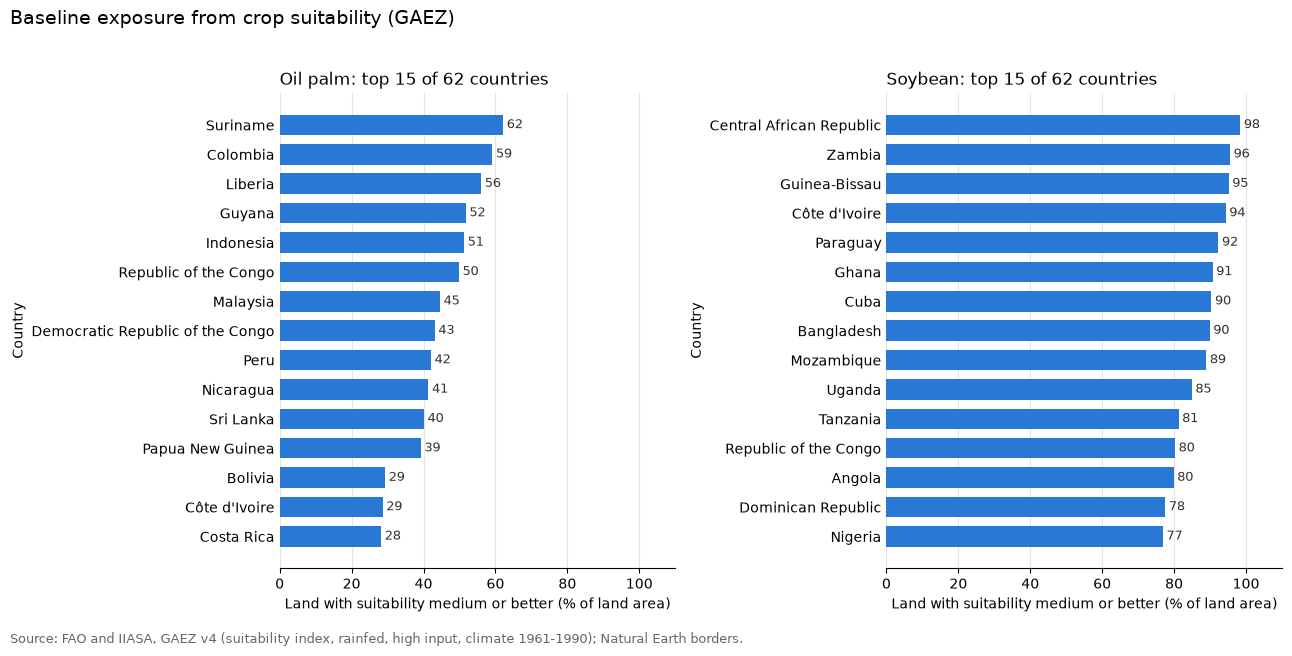

In [8]:
# Top 15 countries by suitability exposure, one panel per crop
SOURCE = ("Source: FAO and IIASA, GAEZ v4 (suitability index, rainfed, high input, climate 1961-1990); "
          "Natural Earth borders.")
TITLES = {"palm": "Oil palm", "soy": "Soybean"}

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, crop in zip(axes, CROPS):
    top = gaez.nlargest(15, f"exposure_gaez_{crop}").sort_values(f"exposure_gaez_{crop}")
    values = top[f"exposure_gaez_{crop}"] * 100
    ax.barh(top["country"], values, color="#2a78d6", height=0.7)
    for y, value in enumerate(values):
        ax.text(value + 1, y, f"{value:.0f}", va="center", fontsize=9, color="#333333")
    ax.set_title(f"{TITLES[crop]}: top 15 of 62 countries", loc="left", fontsize=12)
    ax.set_xlabel("Land with suitability medium or better (% of land area)")
    ax.set_ylabel("Country")
    ax.set_xlim(0, 110)
    ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)

fig.suptitle("Baseline exposure from crop suitability (GAEZ)", x=0.01, ha="left", fontsize=14)
fig.text(0.01, 0.005, SOURCE, fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.03, 1, 0.96))
if os.path.isdir(FIGURES):
    fig.savefig(FIGURES + "gaez_exposure_top15.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Comparison with the FAOSTAT exposure

In [9]:
comp = gaez.merge(faostat[["iso3", "exposure_palm", "exposure_soy"]], on="iso3", validate="one_to_one")

rows = []
for crop in CROPS:
    g, f = comp[f"exposure_gaez_{crop}"], comp[f"exposure_{crop}"]
    producers = f > 0
    rows.append({
        "crop": crop,
        "pearson_all": g.corr(f),
        "spearman_all": g.corr(f, method="spearman"),
        "spearman_producers": g[producers].corr(f[producers], method="spearman"),
        "faostat_exposed": int(producers.sum()),
        "gaez_exposed": int((g > 0).sum()),
        "exposed_in_both": int((producers & (g > 0)).sum()),
        "gaez_only": int((~producers & (g > 0)).sum()),
        "faostat_only": int((producers & (g == 0)).sum()),
    })
pd.DataFrame(rows).set_index("crop").round(2)

,pearson_all,spearman_all,spearman_producers,faostat_exposed,gaez_exposed,exposed_in_both,gaez_only,faostat_only
crop,,,,,,,,
palm,0.18,0.44,0.03,37,46,34,12,3
soy,0.12,-0.02,0.12,43,62,43,19,0


In [10]:
# Correlation of the GAEZ variants with each other (are the choices important?)
for crop in CROPS:
    variants = [f"exposure_gaez_{crop}"] + sorted(c for c in comp.columns if c.startswith(f"{crop}_"))
    print(crop)
    print(comp[variants + [f"exposure_{crop}"]].corr(method="spearman").round(2).to_string(), "\n")

palm
                      exposure_gaez_palm  palm_mean_index_high  palm_share_high_2500  palm_share_high_5500  palm_share_low_4000  palm_share_vs_s_low  exposure_palm
exposure_gaez_palm                  1.00                  0.94                  0.91                  0.94                 0.82                 0.72           0.44
palm_mean_index_high                0.94                  1.00                  0.98                  0.85                 0.90                 0.82           0.44
palm_share_high_2500                0.91                  0.98                  1.00                  0.80                 0.90                 0.81           0.43
palm_share_high_5500                0.94                  0.85                  0.80                  1.00                 0.72                 0.65           0.41
palm_share_low_4000                 0.82                  0.90                  0.90                  0.72                 1.00                 0.91           0.42
palm_share_

In [11]:
# Countries exposed by FAOSTAT but not by GAEZ, and the reverse (largest values)
for crop in CROPS:
    g, f = f"exposure_gaez_{crop}", f"exposure_{crop}"
    print(f"{crop}: FAOSTAT > 0, GAEZ = 0:",
          comp.loc[(comp[f] > 0) & (comp[g] == 0), "country"].tolist())
    print(f"{crop}: highest GAEZ with FAOSTAT = 0:",
          comp.loc[comp[f] == 0].nlargest(5, g)[["country", g]].round(2).values.tolist(), "\n")

palm: FAOSTAT > 0, GAEZ = 0: ['Angola', 'Guinea', 'Guinea-Bissau']
palm: highest GAEZ with FAOSTAT = 0: [['Guyana', 0.52], ['Sri Lanka', 0.4], ['Bolivia', 0.29], ['Belize', 0.22], ['Vanuatu', 0.16]] 

soy: FAOSTAT > 0, GAEZ = 0: []
soy: highest GAEZ with FAOSTAT = 0: [['Central African Republic', 0.98], ['Guinea-Bissau', 0.95], ['Ghana', 0.91], ['Cuba', 0.9], ['Bangladesh', 0.9]] 



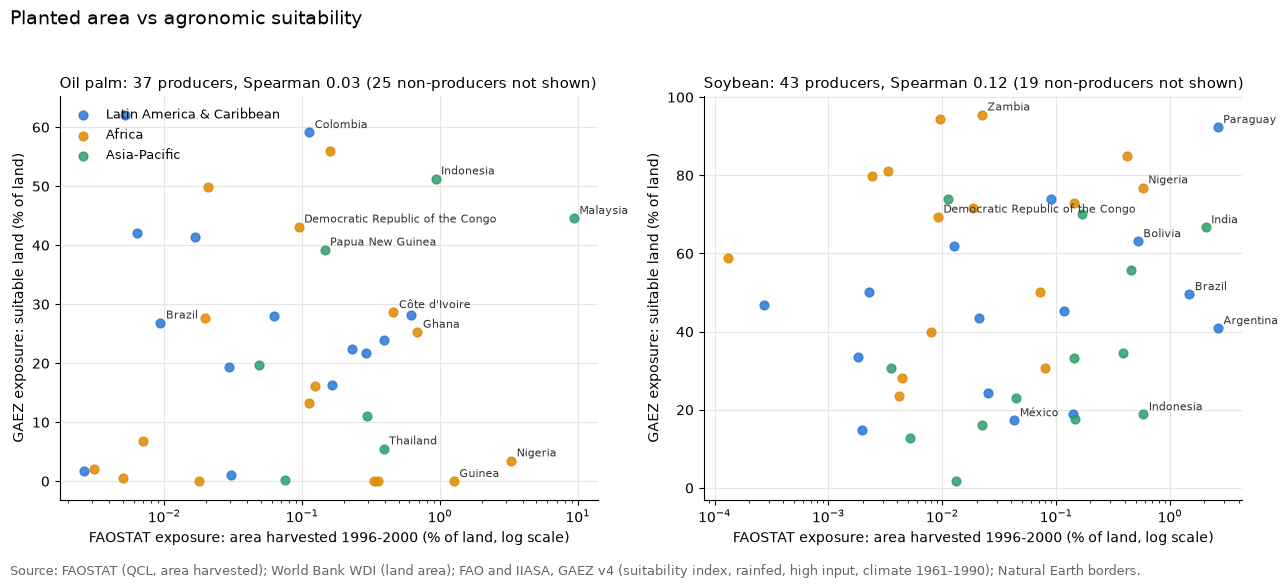

In [12]:
# Scatter: FAOSTAT exposure (log scale, producers only) against GAEZ exposure
LABEL = {"palm": ["MYS", "IDN", "NGA", "GIN", "GHA", "CIV", "COD", "BRA", "COL", "PNG", "THA"],
         "soy": ["ARG", "PRY", "BRA", "IND", "IDN", "NGA", "BOL", "COD", "USA", "MEX", "ZMB"]}
COLORS = {"Latin America & Caribbean": "#2a78d6", "Africa": "#e08a00", "Asia-Pacific": "#2e9e6b"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
for ax, crop in zip(axes, CROPS):
    d = comp[comp[f"exposure_{crop}"] > 0]
    zero = comp[comp[f"exposure_{crop}"] == 0]
    for region, color in COLORS.items():
        r = d[d["region"] == region]
        ax.scatter(r[f"exposure_{crop}"] * 100, r[f"exposure_gaez_{crop}"] * 100, s=40, color=color,
                   alpha=0.85, label=region)
    for _, row in d[d["iso3"].isin(LABEL[crop])].iterrows():
        ax.annotate(row["country"], (row[f"exposure_{crop}"] * 100, row[f"exposure_gaez_{crop}"] * 100),
                    xytext=(4, 3), textcoords="offset points", fontsize=8, color="#333333")
    rho = d[f"exposure_gaez_{crop}"].corr(d[f"exposure_{crop}"], method="spearman")
    ax.set_xscale("log")
    ax.set_title(f"{TITLES[crop]}: {len(d)} producers, Spearman {rho:.2f} "
                 f"({len(zero)} non-producers not shown)", loc="left", fontsize=11)
    ax.set_xlabel("FAOSTAT exposure: area harvested 1996-2000 (% of land, log scale)")
    ax.set_ylabel("GAEZ exposure: suitable land (% of land)")
    ax.grid(color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=9, loc="upper left")

fig.suptitle("Planted area vs agronomic suitability", x=0.01, ha="left", fontsize=14)
fig.text(0.01, 0.005, "Source: FAOSTAT (QCL, area harvested); World Bank WDI (land area); " + SOURCE[8:],
         fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.03, 1, 0.95))
if os.path.isdir(FIGURES):
    fig.savefig(FIGURES + "gaez_vs_faostat.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Regression panel

In [13]:
from linearmodels.iv import IV2SLS
from linearmodels.panel import PanelOLS

START_YEAR, END_YEAR = 2001, 2023  # DeDuCE coverage
panel_raw = pd.read_csv(BASE + "processed/shock_panel.csv")
deduce = pd.read_csv(BASE + "processed/deduce_selected_commodities.csv")
prices = pd.read_csv(BASE + "processed/commodity_prices_annual.csv")

DEDUCE_NAME = {"palm": "Oil palm fruit", "soy": "Soya beans"}
PRICE_NAME = {"palm": "Palm oil", "soy": "Soybeans"}
TOP2 = {"palm": ["IDN", "MYS"], "soy": ["ARG", "BRA"]}  # largest producers, may move the world price
TOP3 = {"palm": ["IDN", "MYS", "NGA"], "soy": ["ARG", "BRA", "PRY"]}

# Outcomes: crop deforestation (DeDuCE) as % of tree cover in 2000, asinh and log(1 + x)
panel = panel_raw[panel_raw["year"].between(START_YEAR, END_YEAR)].copy()
for crop in CROPS:
    defor = (deduce.loc[deduce["commodity"] == DEDUCE_NAME[crop], ["iso3", "year", "defor_ha"]]
                   .rename(columns={"defor_ha": f"defor_{crop}_ha"}))
    panel = panel.merge(defor, on=["iso3", "year"], how="left", validate="one_to_one")
    rate = panel[f"defor_{crop}_ha"].fillna(0.0) / panel["extent_2000_ha"] * 100
    panel[f"y_{crop}"] = np.arcsinh(rate)
    panel[f"y_{crop}_log1p"] = np.log1p(rate)
assert len(panel) == 62 * (END_YEAR - START_YEAR + 1) == 1426

# Log real world prices: lags 1-3 and lead 1 of the crop price, lag 1 of crude oil and wheat
series = {**{PRICE_NAME[c]: c for c in CROPS}, "Crude oil, average": "crude", "Wheat, US HRW": "wheat"}
wide = (prices[prices["commodity"].isin(series)]
        .pivot(index="year", columns="commodity", values="log_price_real").rename(columns=series))
assert (np.diff(wide.index) == 1).all()
price_terms = pd.DataFrame(index=wide.index)
for crop in CROPS:
    for name, shift in {"l1": 1, "l2": 2, "l3": 3, "f1": -1}.items():
        price_terms[f"p_{crop}_{name}"] = wide[crop].shift(shift)
price_terms["p_crude_l1"] = wide["crude"].shift(1)
price_terms["p_wheat_l1"] = wide["wheat"].shift(1)
price_terms = price_terms.reset_index()

# All exposure measures in one table (FAOSTAT from notebooks 3 and 4, GAEZ from section 2)
expo = gaez.merge(faostat[["iso3", "exposure_palm", "exposure_soy"]], on="iso3", validate="one_to_one")
for crop in CROPS:
    expo[f"fao_{crop}"] = expo[f"exposure_{crop}"]
    expo[f"gaez_{crop}"] = expo[f"exposure_gaez_{crop}"]

In [14]:
def build_reg(crop, exposure_col):
    """Country-year panel with Exposure x price terms for one crop and one exposure measure."""
    d = (panel.merge(expo[["iso3", exposure_col]].rename(columns={exposure_col: "E"}), on="iso3",
                     validate="many_to_one")
              .merge(price_terms, on="year", validate="many_to_one"))
    for term in ["l1", "l2", "l3", "f1"]:
        d[f"x_{term}"] = d["E"] * d[f"p_{crop}_{term}"]
    d["x_crude"] = d["E"] * d["p_crude_l1"]
    d["x_wheat"] = d["E"] * d["p_wheat_l1"]
    d["x_trend"] = d["E"] * (d["year"] - START_YEAR)
    d["x_high"] = (d["E"] > expo[exposure_col].median()).astype(float) * d[f"p_{crop}_l1"]
    d["y"] = d[f"y_{crop}"]
    d["y_log1p"] = d[f"y_{crop}_log1p"]
    d["region_year"] = pd.factorize(d["region"] + d["year"].astype(str))[0]
    assert np.isfinite(d.filter(regex="^x_|^y")).all().all()
    return d.set_index(["iso3", "year"]).sort_index()


def fit(data, y, xs, region_year=False):
    """Fixed effects regression with standard errors clustered by country."""
    if region_year:
        model = PanelOLS(data[y], data[xs], entity_effects=True, other_effects=data[["region_year"]])
    else:
        model = PanelOLS(data[y], data[xs], entity_effects=True, time_effects=True)
    return model.fit(cov_type="clustered", cluster_entity=True)


def without(data, codes):
    return data[~data.index.get_level_values("iso3").isin(codes)]


EXPOSURES = {"FAOSTAT": "fao", "GAEZ": "gaez"}
regs = {(crop, label): build_reg(crop, f"{prefix}_{crop}") for crop in CROPS for label, prefix in EXPOSURES.items()}
print({k: v.shape for k, v in regs.items()})

{('palm', 'FAOSTAT'): (1426, 39), ('palm', 'GAEZ'): (1426, 39), ('soy', 'FAOSTAT'): (1426, 39), ('soy', 'GAEZ'): (1426, 39)}


## 5. Main results: FAOSTAT and GAEZ exposure

In [15]:
def run_specs(crop, label):
    """All specifications for one crop and one exposure measure, one row per reported coefficient."""
    d = regs[(crop, label)]
    sd = expo[f"{EXPOSURES[label]}_{crop}"].std()
    specs = [
        # name, data, outcome, regressors, reported term, region x year FE, same scale as main
        ("Main: price t-1", d, "y", ["x_l1"], "x_l1", False, True),
        ("Price t-2 alone", d, "y", ["x_l2"], "x_l2", False, True),
        ("Price t-3 alone", d, "y", ["x_l3"], "x_l3", False, True),
        ("Placebo: price t+1", d, "y", ["x_f1"], "x_f1", False, True),
        ("Placebo: wheat price t-1", d, "y", ["x_wheat"], "x_wheat", False, True),
        ("Without the 2 largest producers", without(d, TOP2[crop]), "y", ["x_l1"], "x_l1", False, True),
        ("Crude oil control", d, "y", ["x_l1", "x_crude"], "x_l1", False, True),
        ("Region x year FE", d, "y", ["x_l1"], "x_l1", True, True),
        ("Exposure x linear trend", d, "y", ["x_l1", "x_trend"], "x_l1", False, True),
        ("log(1 + rate) outcome", d, "y_log1p", ["x_l1"], "x_l1", False, True),
        ("GFW agricultural loss (log rate)", d, "log_agri_loss_rate", ["x_l1"], "x_l1", False, False),
        ("Binned: above median exposure", d, "y", ["x_high"], "x_high", False, False),
    ]
    rows = []
    for name, data, y, xs, term, ry, same_scale in specs:
        res = fit(data, y, xs, region_year=ry)
        ci = res.conf_int().loc[term]
        scale = sd if same_scale and term != "x_high" else np.nan
        rows.append({"crop": crop, "exposure": label, "specification": name, "coef": res.params[term],
                     "se": res.std_errors[term], "p_value": res.pvalues[term], "ci_low": ci["lower"],
                     "ci_high": ci["upper"], "n": int(res.nobs), "sd_exposure": scale})
    return pd.DataFrame(rows)


results = pd.concat([run_specs(c, e) for c in CROPS for e in EXPOSURES], ignore_index=True)
# Standardised effect: one standard deviation more exposure, one log point higher price
for col in ["coef", "ci_low", "ci_high"]:
    results[f"{col}_sd"] = results[col] * results["sd_exposure"]

table = results.assign(cell=lambda r: r["coef"].map("{:.3f}".format) + " (p=" + r["p_value"].map("{:.3f}".format) + ")")
table.pivot(index="specification", columns=["crop", "exposure"], values="cell").loc[results["specification"].unique()]

crop                                          palm                    \
exposure                                   FAOSTAT              GAEZ   
specification                                                          
Main: price t-1                    2.152 (p=0.000)   0.047 (p=0.149)   
Price t-2 alone                    2.725 (p=0.000)   0.058 (p=0.138)   
Price t-3 alone                    2.961 (p=0.000)   0.048 (p=0.224)   
Placebo: price t+1                 0.223 (p=0.682)   0.021 (p=0.338)   
Placebo: wheat price t-1           0.881 (p=0.012)   0.038 (p=0.119)   
Without the 2 largest producers    1.610 (p=0.038)   0.000 (p=0.983)   
Crude oil control                  1.723 (p=0.000)  -0.017 (p=0.533)   
Region x year FE                   2.132 (p=0.000)   0.054 (p=0.150)   
Exposure x linear trend            0.995 (p=0.045)   0.098 (p=0.127)   
log(1 + rate) outcome              1.840 (p=0.000)   0.039 (p=0.148)   
GFW agricultural loss (log rate)  -1.910 (p=0.352)  -0.202 (p=0.582)   
Binned: above median exposure      0.016 (p=0.069)   0.011 (p=0.216)   

crop                                            soy                    
exposure                                    FAOSTAT              GAEZ  
specification                                                          
Main: price t-1                    -2.842 (p=0.003)   0.007 (p=0.456)  
Price t-2 alone                    -3.755 (p=0.006)   0.011 (p=0.323)  
Price t-3 alone                    -3.502 (p=0.010)   0.013 (p=0.230)  
Placebo: price t+1                 -0.871 (p=0.052)   0.004 (p=0.411)  
Placebo: wheat price t-1           -1.736 (p=0.002)   0.003 (p=0.669)  
Without the 2 largest producers    -1.669 (p=0.157)   0.004 (p=0.630)  
Crude oil control                  -4.035 (p=0.112)   0.014 (p=0.108)  
Region x year FE                   -2.688 (p=0.006)   0.000 (p=0.975)  
Exposure x linear trend             1.480 (p=0.441)  -0.006 (p=0.483)  
log(1 + rate) outcome              -2.623 (p=0.003)   0.006 (p=0.437)  
GFW agricultural loss (log rate)  -23.555 (p=0.035)   0.296 (p=0.463)  
Binned: above median exposure      -0.007 (p=0.213)   0.009 (p=0.113)

In [16]:
# Standardised coefficients (comparable across exposure measures), main specification
results.loc[results["specification"].eq("Main: price t-1"),
            ["crop", "exposure", "coef", "sd_exposure", "coef_sd", "ci_low_sd", "ci_high_sd", "p_value"]].round(4)

,crop,exposure,coef,sd_exposure,coef_sd,ci_low_sd,ci_high_sd,p_value
0,palm,FAOSTAT,2.1523,0.0125,0.0270,0.0248,0.0292,0.0000
12,palm,GAEZ,0.0465,0.1880,0.0087,-0.0031,0.0206,0.1495
24,soy,FAOSTAT,-2.8421,0.0056,-0.0159,-0.0265,-0.0052,0.0035
36,soy,GAEZ,0.0066,0.2890,0.0019,-0.0031,0.0069,0.4559


In [17]:
def wild_cluster_p(data, y, x, draws=9999, seed=2026):
    """Restricted wild cluster bootstrap (Rademacher) for one regressor with country and year FE."""
    Y_mat = data[y].unstack("year").to_numpy()
    X_mat = data[x].unstack("year").to_numpy()
    assert not (np.isnan(Y_mat).any() or np.isnan(X_mat).any())  # balanced panel

    def within(a):
        return a - a.mean(1, keepdims=True) - a.mean(0, keepdims=True) + a.mean()

    y_w, x_w = within(Y_mat), within(X_mat)
    n_g = y_w.shape[0]
    h = (x_w ** 2).sum(1)
    s = (x_w * y_w).sum(1)
    H = h.sum()

    beta = s.sum() / H
    t_obs = beta / (np.sqrt(((s - beta * h) ** 2).sum()) / H)

    # Under the null the residuals are the demeaned outcome; year means are re-absorbed in each draw
    w = np.random.default_rng(seed).choice([-1.0, 1.0], size=(draws, n_g))
    beta_star = (w * s).sum(1) / H
    scores = w * s - (w @ y_w / n_g) @ x_w.T - beta_star[:, None] * h
    t_star = beta_star / (np.sqrt((scores ** 2).sum(1)) / H)
    return beta, t_obs, float((np.abs(t_star) >= abs(t_obs)).mean())


rows = []
for (crop, label), d in regs.items():
    cases = {
        "Main: price t-1": (d, "x_l1"),
        "Without the 3 largest producers": (without(d, TOP3[crop]), "x_l1"),
        "Placebo: wheat price t-1": (d, "x_wheat"),
        "Placebo: price t+1": (d, "x_f1"),
    }
    for name, (data, x) in cases.items():
        beta, t_obs, p_boot = wild_cluster_p(data, "y", x)
        res = fit(data, "y", [x])
        assert np.isclose(beta, res.params[x])
        rows.append({"crop": crop, "exposure": label, "specification": name, "coef": beta,
                     "clustered_p": res.pvalues[x], "wild_bootstrap_p": p_boot,
                     "countries": data.index.get_level_values("iso3").nunique()})
boot = pd.DataFrame(rows)
boot.round(4)

,crop,exposure,specification,coef,clustered_p,wild_bootstrap_p,countries
0,palm,FAOSTAT,Main: price t-1,2.1523,0.0000,0.0580,62
1,palm,FAOSTAT,Without the 3 largest producers,-1.2519,0.4566,0.9287,59
2,palm,FAOSTAT,Placebo: wheat price t-1,0.8814,0.0118,0.2774,62
3,palm,FAOSTAT,Placebo: price t+1,0.2226,0.6822,0.5193,62
4,palm,GAEZ,Main: price t-1,0.0465,0.1495,0.2171,62
5,palm,GAEZ,Without the 3 largest producers,0.0049,0.3881,0.3640,59
6,palm,GAEZ,Placebo: wheat price t-1,0.0383,0.1190,0.0729,62
7,palm,GAEZ,Placebo: price t+1,0.0205,0.3385,0.4581,62
8,soy,FAOSTAT,Main: price t-1,-2.8421,0.0035,0.1648,62
9,soy,FAOSTAT,Without the 3 largest producers,0.3900,0.3410,0.3881,59


In [18]:
# GAEZ variants: does the threshold, the input level or the variable change the main result?
VARIANTS = {
    "High input, index >= 4000 (main)": "exposure_gaez_{c}",
    "High input, index >= 2500": "{c}_share_high_2500",
    "High input, index >= 5500": "{c}_share_high_5500",
    "High input, mean index": "{c}_mean_index_high",
    "Low input, index >= 4000": "{c}_share_low_4000",
    "Low input, very suitable or suitable share": "{c}_share_vs_s_low",
}
rows = []
for crop in CROPS:
    for name, pattern in VARIANTS.items():
        col = pattern.format(c=crop)
        res = fit(build_reg(crop, col), "y", ["x_l1"])
        ci = res.conf_int().loc["x_l1"]
        sd = expo[col].std()
        rows.append({"crop": crop, "variant": name, "coef_sd": res.params["x_l1"] * sd,
                     "ci_low_sd": ci["lower"] * sd, "ci_high_sd": ci["upper"] * sd, "p_value": res.pvalues["x_l1"]})
pd.DataFrame(rows).round(4)

,crop,variant,coef_sd,ci_low_sd,ci_high_sd,p_value
0,palm,"High input, index >= 4000 (main)",0.0087,-0.0031,0.0206,0.1495
1,palm,"High input, index >= 2500",0.0060,-0.0027,0.0147,0.1743
2,palm,"High input, index >= 5500",0.0132,-0.0017,0.0282,0.0834
3,palm,"High input, mean index",0.0085,-0.0024,0.0194,0.1266
4,palm,"Low input, index >= 4000",0.0003,-0.0043,0.0049,0.9020
5,palm,"Low input, very suitable or suitable share",-0.0009,-0.0073,0.0054,0.7708
6,soy,"High input, index >= 4000 (main)",0.0019,-0.0031,0.0069,0.4559
7,soy,"High input, index >= 2500",0.0021,-0.0030,0.0072,0.4239
8,soy,"High input, index >= 5500",0.0024,-0.0016,0.0065,0.2358
9,soy,"High input, mean index",0.0023,-0.0028,0.0074,0.3768


In [19]:
# Leave one country out (GAEZ, main specification): range of the coefficient and most influential countries
rows = []
for crop in CROPS:
    d = regs[(crop, "GAEZ")]
    for iso3 in d.index.get_level_values("iso3").unique():
        res = fit(without(d, [iso3]), "y", ["x_l1"])
        rows.append({"crop": crop, "dropped": iso3, "coef": res.params["x_l1"], "p_value": res.pvalues["x_l1"]})
loo = pd.DataFrame(rows)
for crop in CROPS:
    l = loo[loo["crop"] == crop].sort_values("coef")
    full = results.query("crop == @crop and exposure == 'GAEZ' and specification == 'Main: price t-1'")["coef"].iloc[0]
    print(f"{crop}: full sample {full:.4f} | leave-one-out range {l['coef'].min():.4f} to {l['coef'].max():.4f} | "
          f"p < 0.05 in {(l['p_value'] < 0.05).sum()} of {len(l)}")
    print("   lowest when dropping:", l.head(3)[["dropped", "coef"]].round(4).values.tolist(),
          "| highest when dropping:", l.tail(3)[["dropped", "coef"]].round(4).values.tolist())

palm: full sample 0.0465 | leave-one-out range 0.0218 to 0.0535 | p < 0.05 in 0 of 62
   lowest when dropping: [['MYS', 0.0218], ['IDN', 0.0281], ['THA', 0.0461]] | highest when dropping: [['GUY', 0.0509], ['NGA', 0.0512], ['SUR', 0.0535]]
soy: full sample 0.0066 | leave-one-out range 0.0036 to 0.0138 | p < 0.05 in 1 of 62
   lowest when dropping: [['MWI', 0.0036], ['ARG', 0.0042], ['NGA', 0.0044]] | highest when dropping: [['ZWE', 0.007], ['COL', 0.0072], ['PRY', 0.0138]]


## 6. Event study with GAEZ exposure

In [20]:
YEARS = list(range(START_YEAR + 1, END_YEAR + 1))
events = {}
for crop in CROPS:
    d = regs[(crop, "GAEZ")].copy()
    year_index = d.index.get_level_values("year")
    for y in YEARS:
        d[f"ex_{y}"] = d["E"] * (year_index == y).astype(float)
    res = fit(d, "y", [f"ex_{y}" for y in YEARS])
    ci = res.conf_int()
    sd = expo[f"gaez_{crop}"].std()
    es = pd.DataFrame({"year": YEARS,
                       "coef": [res.params[f"ex_{y}"] * sd for y in YEARS],
                       "ci_low": [ci.loc[f"ex_{y}", "lower"] * sd for y in YEARS],
                       "ci_high": [ci.loc[f"ex_{y}", "upper"] * sd for y in YEARS]})
    es = pd.concat([pd.DataFrame({"year": [START_YEAR], "coef": [0.0], "ci_low": [0.0], "ci_high": [0.0]}), es])
    events[crop] = es.merge(price_terms[["year", f"p_{crop}_l1"]], on="year")
    e = events[crop].iloc[1:]
    print(f"{crop}: correlation of yearly coefficients with the t-1 price: {e['coef'].corr(e[f'p_{crop}_l1']):.3f} | "
          f"years with 95% CI excluding 0: {e.loc[(e['ci_low'] > 0) | (e['ci_high'] < 0), 'year'].tolist()}")

palm: correlation of yearly coefficients with the t-1 price: 0.320 | years with 95% CI excluding 0: []
soy: correlation of yearly coefficients with the t-1 price: 0.208 | years with 95% CI excluding 0: [2013, 2014]


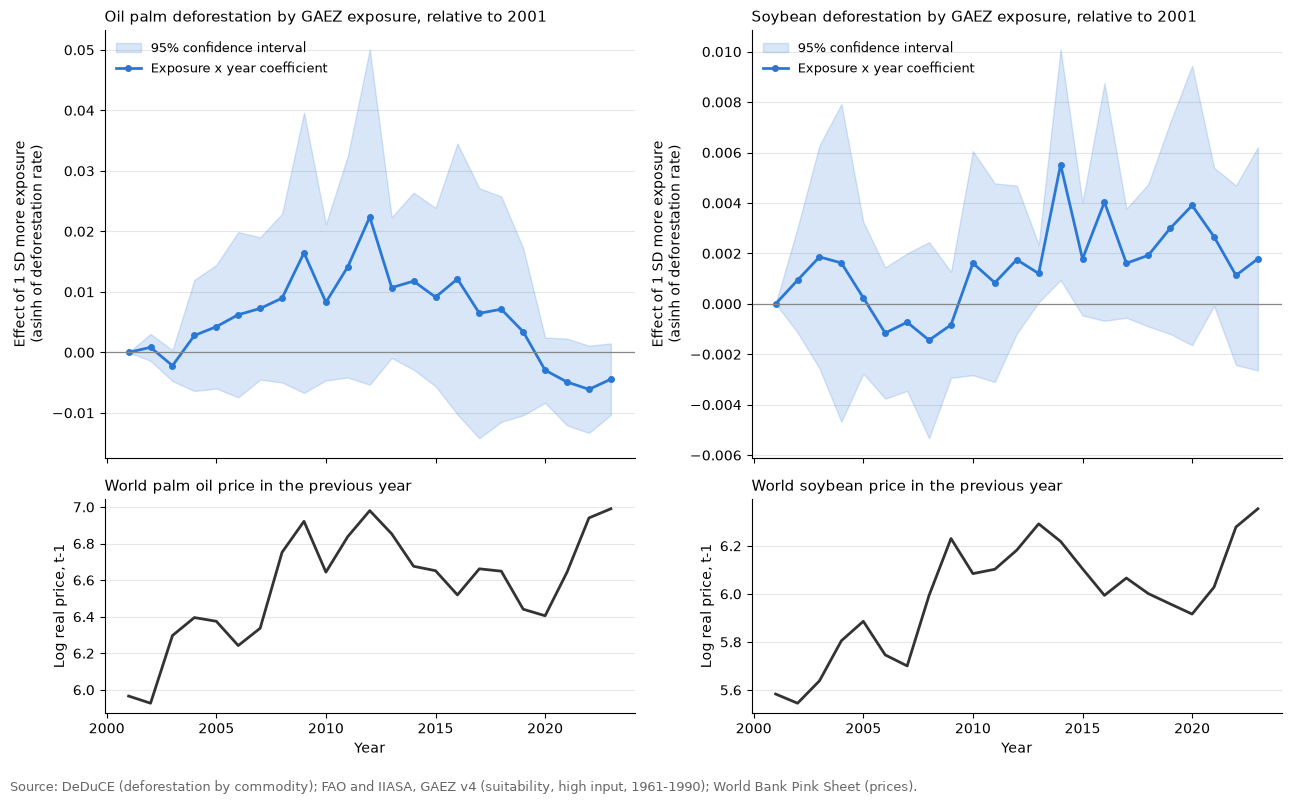

In [21]:
SOURCE_REG = ("Source: DeDuCE (deforestation by commodity); FAO and IIASA, GAEZ v4 (suitability, high input, "
              "1961-1990); World Bank Pink Sheet (prices).")
PRICE_LABEL = {"palm": "palm oil", "soy": "soybean"}

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for j, crop in enumerate(CROPS):
    es = events[crop]
    ax = axes[0, j]
    ax.fill_between(es["year"], es["ci_low"], es["ci_high"], color="#2a78d6", alpha=0.18, label="95% confidence interval")
    ax.plot(es["year"], es["coef"], color="#2a78d6", linewidth=2, marker="o", markersize=4,
            label="Exposure x year coefficient")
    ax.axhline(0, color="#888888", linewidth=0.9)
    ax.set_title(f"{TITLES[crop]} deforestation by GAEZ exposure, relative to 2001", loc="left", fontsize=11)
    ax.set_ylabel("Effect of 1 SD more exposure\n(asinh of deforestation rate)")
    ax.legend(frameon=False, loc="upper left", fontsize=9)
    ax = axes[1, j]
    ax.plot(es["year"], es[f"p_{crop}_l1"], color="#333333", linewidth=2)
    ax.set_title(f"World {PRICE_LABEL[crop]} price in the previous year", loc="left", fontsize=11)
    ax.set_ylabel("Log real price, t-1")
    ax.set_xlabel("Year")
for ax in axes.ravel():
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, 0.005, SOURCE_REG, fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.03, 1, 1))
if os.path.isdir(FIGURES):
    fig.savefig(FIGURES + "gaez_event_study.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Instrumental variable: FAOSTAT exposure instrumented by GAEZ

In [22]:
def within(series):
    """Two-way demeaning on the balanced panel (removes country and year fixed effects)."""
    m = series.unstack("year")
    w = m.sub(m.mean(axis=1), axis=0).sub(m.mean(axis=0), axis=1) + m.to_numpy().mean()
    return w.stack().rename(series.name)


rows = []
for crop in CROPS:
    d_fao, d_gaez = regs[(crop, "FAOSTAT")], regs[(crop, "GAEZ")]
    iv = pd.DataFrame({"y": d_fao["y"], "x": d_fao["x_l1"], "z": d_gaez["x_l1"]})

    first = fit(iv, "x", ["z"])  # first stage with country and year FE, clustered SE
    w = pd.concat([within(iv[c].rename(c)) for c in ["y", "x", "z"]], axis=1)
    clusters = pd.Series(pd.factorize(w.index.get_level_values("iso3"))[0], index=w.index)
    second = IV2SLS(w["y"], None, w["x"], w["z"]).fit(cov_type="clustered", clusters=clusters)
    ci = second.conf_int().loc["x"]
    rows.append({"crop": crop, "first_stage_coef": first.params["z"],
                 "first_stage_F": (first.params["z"] / first.std_errors["z"]) ** 2,
                 "iv_coef": second.params["x"], "iv_se": second.std_errors["x"], "iv_p": second.pvalues["x"],
                 "iv_ci_low": ci["lower"], "iv_ci_high": ci["upper"],
                 "ols_coef": results.query("crop == @crop and exposure == 'FAOSTAT' and "
                                           "specification == 'Main: price t-1'")["coef"].iloc[0]})
# Rule of thumb: first stage F below 10 means a weak instrument, the IV estimate is not reliable
pd.DataFrame(rows).round(4)

,crop,first_stage_coef,first_stage_F,iv_coef,iv_se,iv_p,iv_ci_low,iv_ci_high,ols_coef
0,palm,0.0119,0.9176,3.9121,2.3054,0.0897,-0.6064,8.4307,2.1523
1,soy,0.0023,1.0188,2.8263,6.0165,0.6385,-8.9658,14.6185,-2.8421


## 8. Summary of specifications

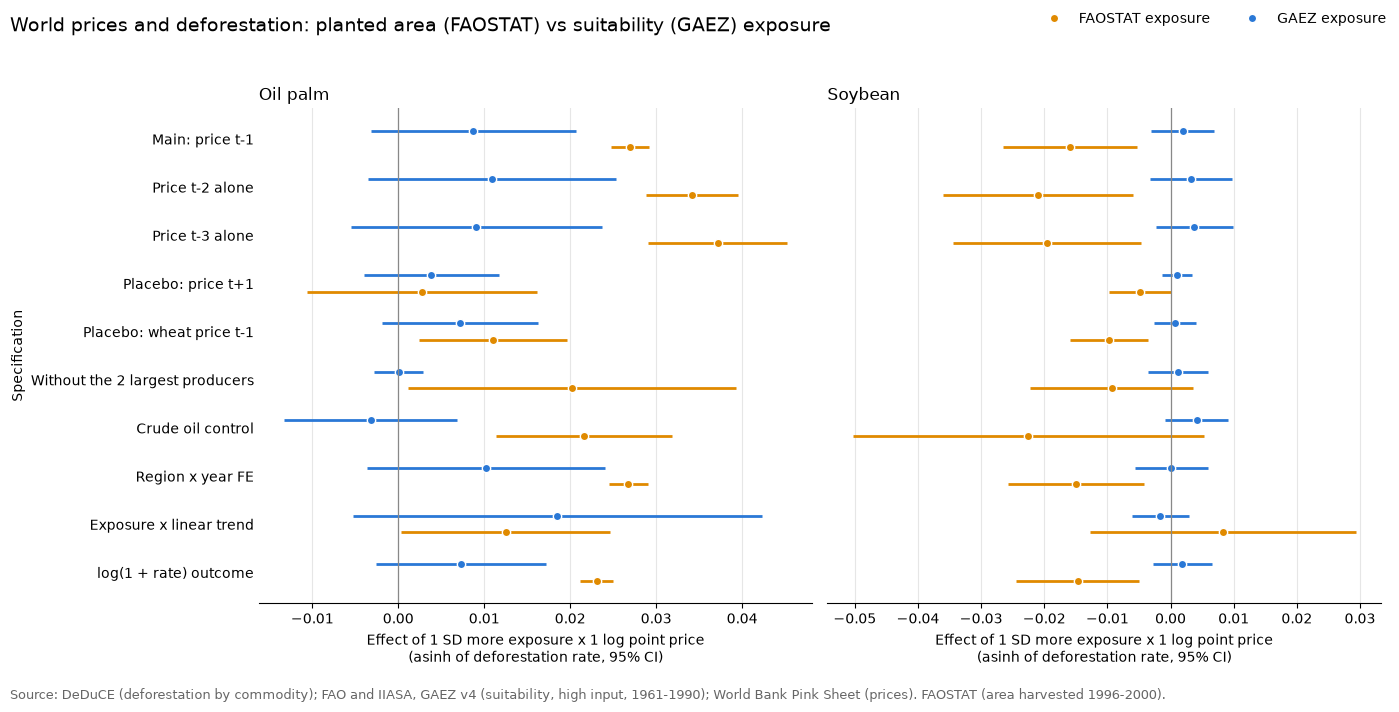

In [23]:
SHOWN = ["Main: price t-1", "Price t-2 alone", "Price t-3 alone", "Placebo: price t+1", "Placebo: wheat price t-1",
         "Without the 2 largest producers", "Crude oil control", "Region x year FE", "Exposure x linear trend",
         "log(1 + rate) outcome"]
STYLE = {"FAOSTAT": ("#e08a00", -0.17), "GAEZ": ("#2a78d6", 0.17)}

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for ax, crop in zip(axes, CROPS):
    for label, (color, offset) in STYLE.items():
        r = (results.query("crop == @crop and exposure == @label").set_index("specification").loc[SHOWN[::-1]]
                    .reset_index())
        pos = np.arange(len(r)) + offset
        ax.hlines(pos, r["ci_low_sd"], r["ci_high_sd"], color=color, linewidth=2)
        ax.plot(r["coef_sd"], pos, "o", color=color, markersize=6, markeredgecolor="white",
                label=f"{label} exposure")
    ax.axvline(0, color="#888888", linewidth=0.9)
    ax.set_yticks(np.arange(len(SHOWN)), SHOWN[::-1])
    ax.set_title(f"{TITLES[crop]}", loc="left", fontsize=12)
    ax.set_xlabel("Effect of 1 SD more exposure x 1 log point price\n(asinh of deforestation rate, 95% CI)")
    ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
axes[0].set_ylabel("Specification")
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc="upper right", ncol=2)

fig.suptitle("World prices and deforestation: planted area (FAOSTAT) vs suitability (GAEZ) exposure",
             x=0.01, ha="left", fontsize=14)
fig.text(0.01, 0.005, SOURCE_REG + " FAOSTAT (area harvested 1996-2000).", fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.03, 1, 0.95))
if os.path.isdir(FIGURES):
    fig.savefig(FIGURES + "gaez_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()